In [1]:
import sys
sys.path.append('../../')


import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import os
import yaml
import pickle
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, roc_curve, auc
from utils.mypath import MyPath
from utils.mypalette import day_palette, als_palette, condition_palette
from statannotations.Annotator import Annotator
from scipy.stats import ttest_ind
import torch
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42


# Set random seed for reproducibility
np.random.seed(42)

batches = ['E1','E2', 'E4']

condition_palette['ALS'] = '#D60078'
condition_palette['CTRL'] = condition_palette['untreated']

# res_dir = '../results'
# general_dir = os.path.join(res_dir, 'cross_task_classification')
# saving_dir = os.path.join(general_dir, 'cross_test')
# model_dir = os.path.join(general_dir, 'regular')
# config_dir = '../configs'
# 
# os.makedirs(saving_dir, exist_ok=True)
# 
# ###
# # LOAD EMBEDDINGS AND ANNOTATIONS, BALANCE DATASET MAKING SURE THAT CTRL UNTR SUBSETS ARE NOT OVERLAPPING
# ###
# 
# annotations, raw_emb = setup_experiment(x, batches)
# annotations['embedding'] = list(raw_emb)

results_dir = '../../results/cross_task_classification_resnet/cross_test/'

kwargs = {'fill': True, 'alpha': 0.2, 'palette': condition_palette, 'linewidth': 1}

/tmp/ipykernel_1496904/1583813217.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')



Batch: E1
        dataset    class  percentage
0  test (cross)     CTRL    3.346457
1  test (cross)  TIChigh    9.055118


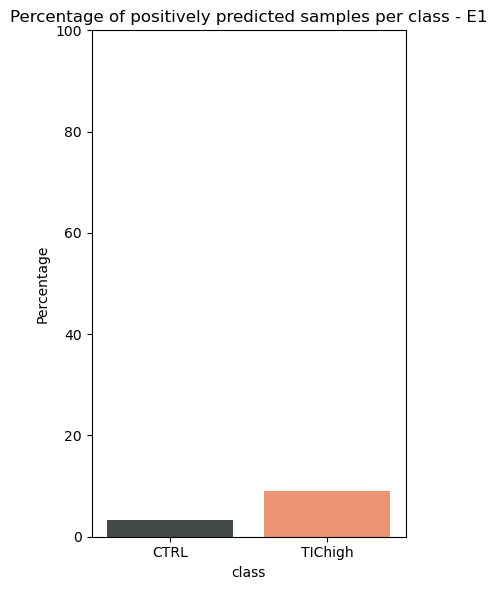


Batch: E2
        dataset    class  percentage
0  test (cross)     CTRL    5.396825
1  test (cross)  TIChigh    6.031746


/tmp/ipykernel_1496904/1583813217.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')


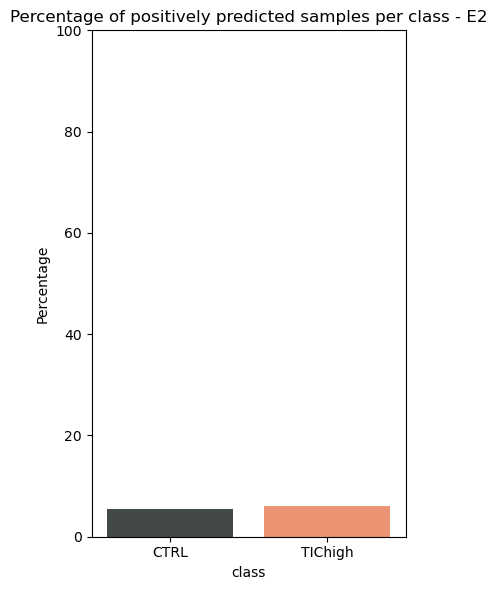

/tmp/ipykernel_1496904/1583813217.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')



Batch: E4
        dataset    class  percentage
0  test (cross)     CTRL   20.905172
1  test (cross)  TIChigh   41.594828


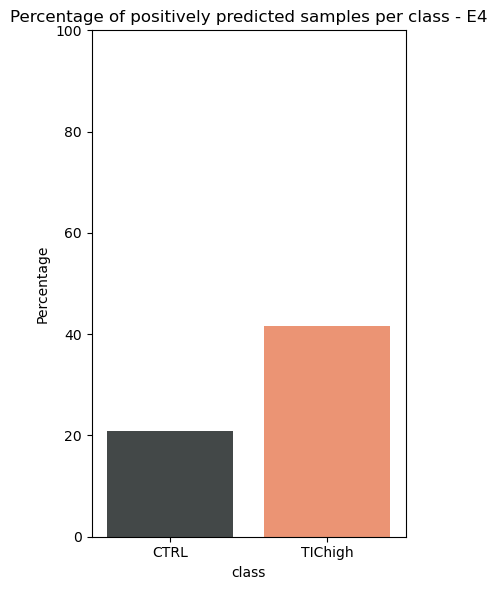

In [2]:
classifiers = ['ALS']
test = 'TIChigh'

# Read saved cross-test result files, compute percentage of positive predictions (>0.5)
# and plot percentage per class for each batch
for b in batches:
    all_dfs = []
    for c in classifiers:
        fp = os.path.join(results_dir, b, f'MODEL_{c}_DATA_{test}_results.csv')
        if not os.path.exists(fp):
            print(f'Missing results file: {fp}')
            continue
        df = pd.read_csv(fp)
        # normalize predicted probability column name if needed
        prob_cols = [col for col in df.columns if 'predicted_probability' in col]
        if len(prob_cols) > 0:
            df = df.rename(columns={prob_cols[0]: 'predicted_probability'})
        if 'predicted_probability' not in df.columns:
            print(f'No predicted_probability column in {fp}; skipping')
            continue
        df['batch'] = b
        df['classifier'] = c
        all_dfs.append(df)

    if len(all_dfs) == 0:
        print(f'No data found for batch {b}')
        continue

    data = pd.concat(all_dfs, ignore_index=True)

    # Compute percentage of samples with predicted_probability > 0.5 per dataset and class
    def pct_pos(g):
        if len(g) == 0:
            return 0.0
        return (g['predicted_probability'] > 0.5).sum() / len(g) * 100

    summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')
    print('\nBatch:', b)
    print(summary)

    # Plot percentage per class with dataset hue
    plt.figure(figsize=(4, 6))
    sns.barplot(data=summary, x='class', y='percentage', hue='class', palette=condition_palette)
    plt.ylim(0, 100)
    plt.ylabel('Percentage')
    plt.title(f'Percentage of positively predicted samples per class - {b}')
    outfp = os.path.join(results_dir, b, f'model_{c}_data_{test}_positive_ratio_{b}.pdf')
    os.makedirs(os.path.dirname(outfp), exist_ok=True)
    plt.tight_layout()
    plt.savefig(outfp)
    plt.show()


Batch: E1
        dataset class  percentage
0  test (cross)   ALS   71.161417
1  test (cross)  CTRL   25.098425


/tmp/ipykernel_1496904/3562115750.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')


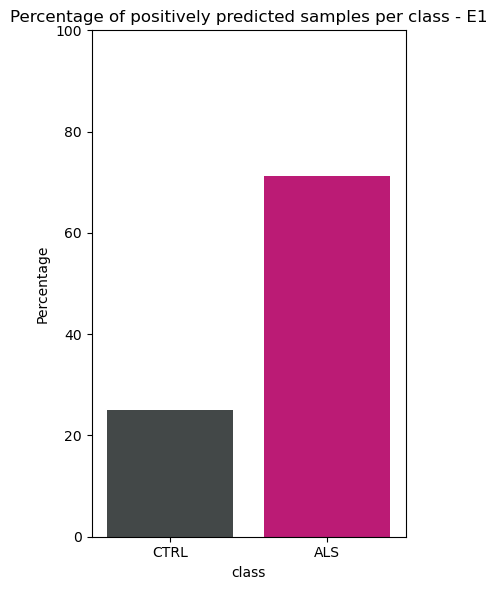

/tmp/ipykernel_1496904/3562115750.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')


Missing results file: ../../results/cross_task_classification_resnet/cross_test/E2/MODEL_TIClow_DATA_ALS_results.csv

Batch: E2
        dataset class  percentage
0  test (cross)   ALS   11.428571
1  test (cross)  CTRL   27.936508


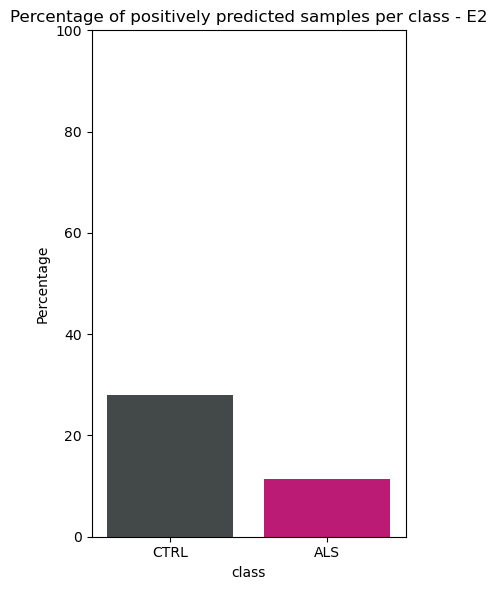


Batch: E4
        dataset class  percentage
0  test (cross)   ALS   56.465517
1  test (cross)  CTRL   26.508621


/tmp/ipykernel_1496904/3562115750.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')


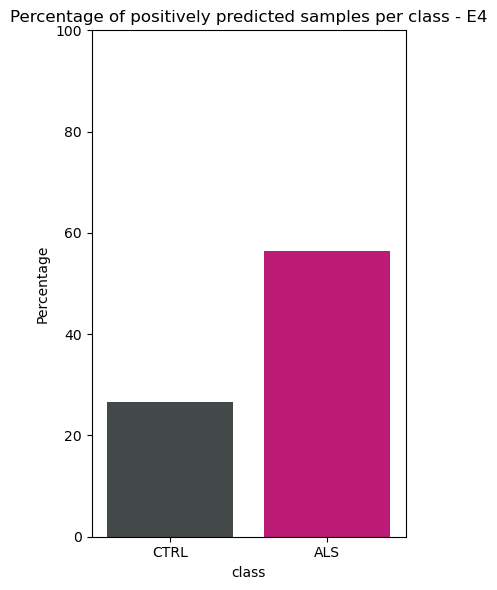

In [4]:
classifiers = ['TIClow', 'TIChigh']
test = 'ALS'

for b in batches:
    all_dfs = []
    for c in classifiers:
        fp = os.path.join(results_dir, b, f'MODEL_{c}_DATA_{test}_results.csv')
        if not os.path.exists(fp):
            print(f'Missing results file: {fp}')
            continue
        df = pd.read_csv(fp)
        # normalize predicted probability column name if needed
        prob_cols = [col for col in df.columns if 'predicted_probability' in col]
        if len(prob_cols) > 0:
            df = df.rename(columns={prob_cols[0]: 'predicted_probability'})
        if 'predicted_probability' not in df.columns:
            print(f'No predicted_probability column in {fp}; skipping')
            continue
        df['batch'] = b
        df['classifier'] = c
        all_dfs.append(df)

    if len(all_dfs) == 0:
        print(f'No data found for batch {b}')
        continue

    data = pd.concat(all_dfs, ignore_index=True)

    # Compute percentage of samples with predicted_probability > 0.5 per dataset and class
    def pct_pos(g):
        if len(g) == 0:
            return 0.0
        return (g['predicted_probability'] > 0.5).sum() / len(g) * 100

    summary = data.groupby(['dataset', 'class']).apply(pct_pos).reset_index(name='percentage')
    print('\nBatch:', b)
    print(summary)

    # Plot percentage per class with dataset hue
    plt.figure(figsize=(4, 6))
    sns.barplot(data=summary, x='class', y='percentage', hue='class', palette=condition_palette, order=['CTRL', 'ALS'])
    plt.ylim(0, 100)
    plt.ylabel('Percentage')
    plt.title(f'Percentage of positively predicted samples per class - {b}')
    outfp = os.path.join(results_dir, b, f'model_{c}_data_{test}_positive_ratio_{b}.pdf')
    os.makedirs(os.path.dirname(outfp), exist_ok=True)
    plt.tight_layout()
    plt.savefig(outfp)
    plt.show()